[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/01_big-picture.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 1 of 21*

# How Data Flows

What a data engineer actually does: the data lifecycle, ETL vs ELT, OLTP vs OLAP, batch vs streaming, and how to think about volume, freshness and reliability. No experience needed.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A data engineer is a city's water engineer: collect it, clean it, store it and pipe it to every home, so that nobody has to think about it.

**What interviewers really test here:** ETL vs ELT, OLTP vs OLAP, batch vs streaming, and whether you ask what the data's for.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What does a data engineer actually do? *(Basics)*
- [ ] 2. ETL by hand: your first pipeline *(Basics)*
- [ ] 3. Two kinds of database: OLTP and OLAP *(Basics)*
- [ ] 4. Batch or streaming? *(Core)*
- [ ] 5. Thinking in numbers *(Core)*
- [ ] 6. The lake, the warehouse and who depends on what *(Core)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Key terms

| Term | Plain meaning |
| --- | --- |
| Pipeline | a series of steps moving data from source to destination |
| ETL / ELT | transform before loading / load raw, then transform |
| Data lake | cheap file storage holding raw data of any shape |
| Data warehouse | a database built for analytics on clean tables |
| Schema | the columns and types data should have |
| SLA | a promise, such as "ready by 8 am" |
| Partition | a piece of a table, often one day |
| Lineage | which data was built from which |

---
# Part 2: Lessons, step by step

## Lesson 1: What does a data engineer actually do?

*Level: Basics*

Imagine a huge city. Water comes from rivers and rain. Before you can drink it, someone must collect it, clean it, store it and pipe it to every home. No one thanks the water engineers until a tap runs dry.



**A data engineer does this for data.** A company's data starts scattered across apps, payment systems and sensors. Analysts, scientists and AI models need it clean, connected and on time. You build the pipes between them.



```text
Sources      Ingest       Store        Transform     Serve        Users
apps    ──▶  collect ──▶  raw lake ──▶ clean, join ─▶ warehouse ─▶ dashboards
payments     in batches   (keep it     and model      or API       ML models
sensors      or streams   all)         the data                    AI apps
```



| Role | Main question | Typical output |
| --- | --- | --- |
| **Data engineer** | Is the right data arriving, correct and on time? | reliable pipelines and tables |
| Data analyst | What happened, and why? | dashboards, reports |
| Data scientist | What will happen? What should we try? | models, experiments |
| ML engineer | How do we run this model in production? | model services |



**What separates good from great?** Beginners ask "does it run?". Strong engineers ask: what if it runs twice? What if yesterday's data arrives today? What if the source adds a column? How will I know it broke before my users do? This course teaches those questions along with the tools, and tools change while these questions don't.

**✏️ Your turn:** you now have what you need for [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 2: ETL by hand: your first pipeline

*Level: Basics*

Every pipeline, however large, does three things. **Extract** takes data from a source. **Transform** cleans and shapes it. **Load** writes it where people can use it.



Say this file arrives:



```python
city,amount
Pune,10
Delhi,5
Pune,x        ← bad value
Pune,2.5
```



| Step | What happens | Result |
| --- | --- | --- |
| Extract | read 4 rows | 4 dictionaries of text |
| Transform | convert amount to a number; "x" fails | 3 good, 1 bad |
| Load | total per city | Delhi 5, Pune 12.5 |



**Lesson 1: never quietly lose data.** The bad row should go somewhere you can look at it, called a **dead-letter** location. Otherwise your total is wrong and nobody knows.



**Lesson 2: keep steps separate.** If extract, transform and load are separate functions, each can be tested alone.



**ETL vs ELT.** Traditionally you cleaned data first (ETL), because storage was expensive. Now storage is cheap and warehouses are powerful, so teams often **load raw data first, then transform it inside the warehouse (ELT)**. If your logic has a bug, the raw data's still there, so you can fix it and rebuild.



**Real data is messy:** CSV values contain commas, so use a real parser. JSON is nested, so you flatten it. Sources send duplicates, so you remove them. Columns change, so you check the schema when data arrives.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q15](#q15), [Q17](#q17), [Q8](#q8), [Q9](#q9), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 3: Two kinds of database: OLTP and OLAP

*Level: Basics*

A shop's till and its yearly accounts need very different things.



|   | OLTP (the till) | OLAP (the accounts) |
| --- | --- | --- |
| Purpose | run the app | analyse the business |
| Typical query | "get order 123" | "revenue by city for 3 years" |
| Rows touched | a few | billions |
| Writes | constant small updates | big scheduled loads |
| Examples | PostgreSQL, MySQL | Snowflake, BigQuery, Redshift |
| Storage | row by row | column by column |



**Why do columns help analytics?** Take 1 million rows, 50 columns of 8 bytes each, and a query that uses just 2 columns:



- **Row store:** reads everything: 1,000,000 × 50 × 8 = **400 MB**.
- **Column store:** reads only 2 columns: 1,000,000 × 2 × 8 = **16 MB**, which is 25 times less.



Similar values also sit next to each other, so they compress well. A file might shrink 4 times, saving 75%. The chart shows how the saving grows with table width.



**This is why you don't run analytics on the production database.** One big report can slow the app for real customers. So data engineers copy data out to a separate analytics system.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

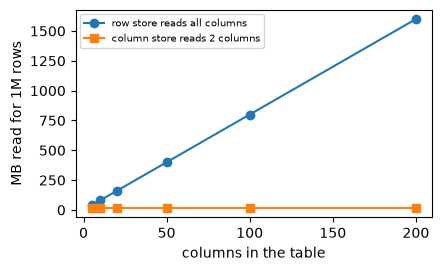

In [2]:
def column_saving():
    widths = np.array([5, 10, 20, 50, 100, 200])
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(widths, 1000000 * widths * 8 / 1e6, "o-", label="row store reads all columns")
    ax.plot(widths, np.full(len(widths), 1000000 * 2 * 8 / 1e6), "s-", label="column store reads 2 columns")
    ax.set_xlabel("columns in the table")
    ax.set_ylabel("MB read for 1M rows")
    ax.legend(fontsize=7)


column_saving()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 4: Batch or streaming?

*Level: Core*

**Batch** is like a bus: it waits, collects passengers, and leaves on a schedule. **Streaming** is like a taxi: each passenger leaves right away.



| Run every | Average wait | Worst wait |
| --- | --- | --- |
| 24 hours | 12 hours | 24 hours |
| 60 minutes | 30 minutes | 60 minutes |
| 1 minute | 30 seconds | 1 minute |



Streaming feels better, so why isn't everything streaming? Because it's harder and more expensive: data arrives out of order, the system must run all day, and fixing mistakes is more difficult.



**Ask: what decision depends on this data, and how quickly?**



- Block a fraudulent card: seconds, so streaming.
- Update a live operations board: minutes, so micro-batch.
- Monthly finance report: a day is fine, so batch.



A very common mistake is building streaming because it sounds advanced, for data that someone reads once a day. Choosing the simpler option is a mark of seniority.



**Freshness** is how old your newest data is. If the latest event loaded was 10 minutes ago and your promise (an **SLA**) is 15 minutes, you're fine. If it's 33 minutes, you've broken it, and someone should be alerted.

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 5: Thinking in numbers

*Level: Core*

Before building anything, estimate. It takes a minute and prevents very expensive mistakes.



**Volume.** 1,000 events per second at 500 bytes each:



- A day has 86,400 seconds, so 86,400,000 events.
- 86,400,000 × 500 bytes = **43.2 GB a day**.
- × 365 = **15.77 TB a year**.



**Time.** Processing 100 GB at 50 MB/s takes 2,000 seconds, or **33 minutes**. With 10 workers and perfect scaling, it's 3.3 minutes. In practice you won't get perfect scaling, for reasons you'll learn in the Spark topics.



**Cost.** 500 GB a day kept for 90 days is 45,000 GB. At a made-up \$0.02 per GB per month, that's \$900 a month. If you compress it 4 times, it's \$225.



**Peaks.** Hourly counts of 100, 100, 400, 200 average 200, but the peak's 400, a ratio of 2. Systems must handle the peak, not the average.



**Reliability multiplies.** A chain of 10 steps, each 99% reliable, succeeds only 0.99¹⁰ = **90.4%** of the time. Run daily, that's about **35 failures a year**. At 99.9% per step, it's about 3.6. So you need retries and alerts, as failure is normal rather than rare. The chart shows how quickly reliability falls as a pipeline gets longer.



| Handy numbers |   |
| --- | --- |
| Seconds in a day | 86,400 (about 10⁵) |
| 1 GB | 1,000 MB |
| 1 TB | 1,000 GB |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

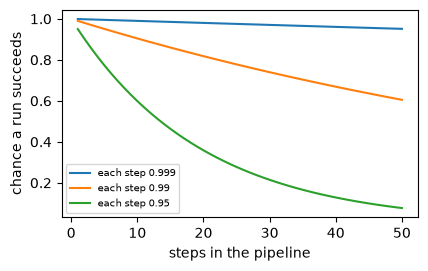

In [3]:
def reliability_chart():
    steps = np.arange(1, 51)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    for p in [0.999, 0.99, 0.95]:
        ax.plot(steps, p ** steps, label=f"each step {p}")
    ax.set_xlabel("steps in the pipeline")
    ax.set_ylabel("chance a run succeeds")
    ax.legend(fontsize=7)


reliability_chart()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q5](#q5), [Q11](#q11), [Q13](#q13), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: The lake, the warehouse and who depends on what

*Level: Core*

**Layers.** Most platforms keep data at several levels of refinement. It's often called the **medallion** pattern:



| Layer | Holds | Who uses it |
| --- | --- | --- |
| Bronze (raw) | exactly what arrived | engineers, to reprocess |
| Silver (clean) | typed, deduplicated, joined | analysts, scientists |
| Gold (business) | metrics ready to use | dashboards, reports |



**Partitioning.** Lakes store files in folders by date, like `lake/orders/year=2026/month=01/day=05/`. A query about one day then reads just one folder, rather than years of data.



**Lineage** is the family tree of your tables. If `clean` breaks, what else is wrong?



```text
raw → clean → daily → dashboard
          └──→ users
```



A failure in `clean` affects daily, users and dashboard. That's a graph search. Knowing this lets you warn the right people before they find out by themselves.



**Your first 90 days on any data team:** learn one pipeline from source to dashboard, find out who uses it, and what they'd notice if it broke.

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
import csv

import io


<a id="q1"></a>
### Q1. Extract: Parse CSV Text

🟢 Warm-up · *The E in ETL*

Turn CSV text with a header row into a list of dictionaries, with all values as strings.

**Examples**

- `text = 'id,name\n1,Asha\n2,Ben\n'` → `[{'id': '1', 'name': 'Asha'}, {'id': '2', 'name': 'Ben'}]`

In [ ]:
def parse_csv(text):
    """
    Turn CSV text with a header row into a list of dictionaries, with all values
    as strings.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(parse_csv, [
    (('id,name\n1,Asha\n2,Ben\n',), [{'id': '1', 'name': 'Asha'}, {'id': '2', 'name': 'Ben'}]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split lines and commas by hand. It breaks if a value contains a comma.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`csv.DictReader` handles quotes and commas in values.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Split lines and commas by hand. It breaks if a value contains a comma.

```python
def parse_csv(text):
    lines = text.strip().split("\n")
    header = lines[0].split(",")
    rows = []
    for line in lines[1:]:
        values = line.split(",")
        row = {}
        for name, value in zip(header, values):
            row[name] = value
        rows.append(row)
    return rows
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `csv.DictReader` handles quotes and commas in values.

```python
def parse_csv(text):
    return list(csv.DictReader(io.StringIO(text)))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split lines and commas by hand. It breaks if a value contains a comma. That costs O(n) time and O(n) space."

"I can do better: `csv.DictReader` handles quotes and commas in values. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/extract-parse-csv-text)

<a id="q2"></a>
### Q2. Transform: Clean One Record

🟢 Warm-up · *The T in ETL*

Given a record with name and amount as text: trim and title-case the name, and convert amount to a float. Return None if the amount isn't a number.

**Examples**

- `rec = {'name': '  asha ', 'amount': '12.50'}` → `{'name': 'Asha', 'amount': 12.5}`
- `rec = {'name': 'ben', 'amount': 'oops'}` → `None`

In [ ]:
def clean_record(rec):
    """
    Given a record with name and amount as text: trim and title-case the name,
    and convert amount to a float. Return None if the amount isn't a number.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clean_record, [
    (({'name': '  asha ', 'amount': '12.50'},), {'name': 'Asha', 'amount': 12.5}),
    (({'name': 'ben', 'amount': 'oops'},), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check each character of the amount.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`try/except ValueError` around `float()`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check each character of the amount.

```python
def clean_record(rec):
    text = rec["amount"]
    if not text or text.count(".") > 1 or not text.replace(".", "").isdigit():
        return None
    return {"name": rec["name"].strip().title(), "amount": float(text)}
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `try/except ValueError` around `float()`.

```python
def clean_record(rec):
    try:
        return {"name": rec["name"].strip().title(), "amount": float(rec["amount"])}
    except ValueError:
        return None
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check each character of the amount. That costs O(n) time and O(n) space."

"I can do better: `try/except ValueError` around `float()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/transform-clean-one-record)

<a id="q3"></a>
### Q3. Load: Good Rows and Bad Rows

🟢 Warm-up · *Don't lose data silently*

Split amounts into good ones (parse as float) and bad ones (kept as they were, to investigate later). Return (good, bad).

**Examples**

- `values = ['1.5', 'x', '2', '']` → `([1.5, 2.0], ['x', ''])`

In [ ]:
def split_rows(values):
    """
    Split amounts into good ones (parse as float) and bad ones (kept as they
    were, to investigate later). Return (good, bad).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split_rows, [
    ((['1.5', 'x', '2', ''],), ([1.5, 2.0], ['x', ''])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with try/except, appending to two lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same, with a small helper. A real pipeline writes bad rows to a dead-letter location.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with try/except, appending to two lists.

```python
def split_rows(values):
    good, bad = [], []
    for v in values:
        try:
            good.append(float(v))
        except ValueError:
            bad.append(v)
    return (good, bad)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The same, with a small helper. A real pipeline writes bad rows to a dead-letter location.

```python
def split_rows(values):
    def parse(v):
        try:
            return float(v)
        except ValueError:
            return None
    parsed = [(v, parse(v)) for v in values]
    return ([p for _, p in parsed if p is not None], [v for v, p in parsed if p is None])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with try/except, appending to two lists. That costs O(n) time and O(n) space."

"I can do better: The same, with a small helper. A real pipeline writes bad rows to a dead-letter location. That's O(n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `values = ['1.5', 'x', '2', '']`

1. parse() returns 1.5
2. ValueError raised: could not convert string to float: 'x'
3. parse() returns None
4. parse() returns 2.0
5. ValueError raised: could not convert string to float: ''
6. parse() returns None
7. split\_rows() returns ([1.5, 2.0], ['x', ''])

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/load-good-rows-and-bad-rows)

<a id="q4"></a>
### Q4. How Much Data per Day?

🟢 Warm-up · *Thinking in volume*

Given events per second and bytes per event, return GB per day and TB per year (10⁹ and 10¹² bytes), rounded to 2 decimals.

**Examples**

- `eps = 1000, size = 500` → `(43.2, 15.77)`
- `eps = 50000, size = 1000` → `(4320.0, 1576.8)`

In [ ]:
def daily_volume(eps, size):
    """
    Given events per second and bytes per event, return GB per day and TB per
    year (10⁹ and 10¹² bytes), rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(daily_volume, [
    ((1000, 500), (43.2, 15.77)),
    ((50000, 1000), (4320.0, 1576.8)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply one step at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One formula for each.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply one step at a time.

```python
def daily_volume(eps, size):
    per_day = eps * 60 * 60 * 24
    bytes_day = per_day * size
    return (round(bytes_day / 1e9, 2), round(bytes_day * 365 / 1e12, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One formula for each.

```python
def daily_volume(eps, size):
    b = eps * size * 86400
    return (round(b / 1e9, 2), round(b * 365 / 1e12, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply one step at a time. That costs O(1) time and O(1) space."

"I can do better: One formula for each. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/how-much-data-per-day)

<a id="q5"></a>
### Q5. How Long to Process It?

🟢 Warm-up · *Will it finish in time?*

Given data size in GB and a speed in MB/s per worker, return the minutes to finish with n workers, assuming perfect scaling, rounded to 2 decimals.

**Examples**

- `gb = 100, mb_per_s = 50, n = 1` → `33.33`
- `gb = 100, mb_per_s = 50, n = 10` → `3.33`

In [ ]:
def process_minutes(gb, mb_per_s, n):
    """
    Given data size in GB and a speed in MB/s per worker, return the minutes to
    finish with n workers, assuming perfect scaling, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(process_minutes, [
    ((100, 50, 1), 33.33),
    ((100, 50, 10), 3.33),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Convert units step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Convert units step by step.

```python
def process_minutes(gb, mb_per_s, n):
    megabytes = gb * 1000
    seconds = megabytes / mb_per_s / n
    return round(seconds / 60, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def process_minutes(gb, mb_per_s, n):
    return round(gb * 1000 / (mb_per_s * n * 60), 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Convert units step by step. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/how-long-to-process-it)

<a id="q6"></a>
### Q6. Data Freshness

🟢 Warm-up · *How old is the data?*

Given the current time and the latest loaded event time (seconds), return the lag in minutes rounded to 1 decimal, and whether it meets the SLA in minutes.

**Examples**

- `now = 10000, latest = 9400, sla = 15` → `(10.0, True)`
- `now = 10000, latest = 8000, sla = 15` → `(33.3, False)`

In [ ]:
def freshness(now, latest, sla):
    """
    Given the current time and the latest loaded event time (seconds), return
    the lag in minutes rounded to 1 decimal, and whether it meets the SLA in
    minutes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(freshness, [
    ((10000, 9400, 15), (10.0, True)),
    ((10000, 8000, 15), (33.3, False)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract, convert, compare.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Subtract, convert, compare.

```python
def freshness(now, latest, sla):
    seconds = now - latest
    minutes = seconds / 60
    return (round(minutes, 1), minutes <= sla)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def freshness(now, latest, sla):
    lag = (now - latest) / 60
    return (round(lag, 1), lag <= sla)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract, convert, compare. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/data-freshness)

<a id="q7"></a>
### Q7. Batch Size vs Latency

🟢 Warm-up · *The core trade-off*

If events arrive evenly and you process every w minutes, return the average and worst wait in minutes before an event is processed, ignoring run time.

**Examples**

- `w = 60` → `(30.0, 60)`
- `w = 1` → `(0.5, 1)`

In [ ]:
def batch_wait(w):
    """
    If events arrive evenly and you process every w minutes, return the average
    and worst wait in minutes before an event is processed, ignoring run time.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batch_wait, [
    ((60,), (30.0, 60)),
    ((1,), (0.5, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Reason it through: the worst waits the full window, and the average half.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A one-liner.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Reason it through: the worst waits the full window, and the average half.

```python
def batch_wait(w):
    worst = w
    average = w / 2
    return (average, worst)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A one-liner.

```python
def batch_wait(w):
    return (w / 2, w)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Reason it through: the worst waits the full window, and the average half. That costs O(1) time and O(1) space."

"I can do better: A one-liner. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/batch-size-vs-latency)

<a id="q8"></a>
### Q8. Parse JSON Lines

🟢 Warm-up · *The standard log format*

Text has one JSON object per line. Return (parsed objects, count of invalid lines).

**Examples**

- `text = '{"a": 1}\nnot json\n{"a": 2}\n'` → `([{'a': 1}, {'a': 2}], 1)`

In [ ]:
import json

def parse_jsonl(text):
    """
    Text has one JSON object per line. Return (parsed objects, count of invalid
    lines).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(parse_jsonl, [
    (('{"a": 1}\nnot json\n{"a": 2}\n',), ([{'a': 1}, {'a': 2}], 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with try/except.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper, so each line is handled the same.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with try/except.

```python
def parse_jsonl(text):
    good, bad = [], 0
    for line in text.strip().split("\n"):
        try:
            good.append(json.loads(line))
        except json.JSONDecodeError:
            bad += 1
    return (good, bad)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper, so each line is handled the same.

```python
def parse_jsonl(text):
    def load(line):
        try:
            return json.loads(line)
        except json.JSONDecodeError:
            return None
    parsed = [load(l) for l in text.splitlines() if l.strip()]
    return ([p for p in parsed if p is not None], parsed.count(None))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with try/except. That costs O(n) time and O(n) space."

"I can do better: A helper, so each line is handled the same. That's O(n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `text = '{"a": 1}\nnot json\n{"a": 2}\n'`

1. load() returns {'a': 1}
2. JSONDecodeError raised: Expecting value: line 1 column 1 (char 0)
3. load() returns None
4. load() returns {'a': 2}
5. parse\_jsonl() returns ([{'a': 1}, {'a': 2}], 1)

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/parse-json-lines)

<a id="q9"></a>
### Q9. Remove Exact Duplicates

🟢 Warm-up · *Sources send things twice*

Keep the first copy of each id, preserving order.

**Examples**

- `rows = [{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}, {'id': 1, 'v': 'a'}]` → `[{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}]`

In [ ]:
def dedupe_rows(rows):
    """
    Keep the first copy of each id, preserving order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dedupe_rows, [
    (([{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}, {'id': 1, 'v': 'a'}],), [{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare against every kept row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set of seen ids.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compare against every kept row.

```python
def dedupe_rows(rows):
    kept = []
    for r in rows:
        if not any(k["id"] == r["id"] for k in kept):
            kept.append(r)
    return kept
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set of seen ids.

```python
def dedupe_rows(rows):
    seen, kept = set(), []
    for r in rows:
        if r["id"] not in seen:
            seen.add(r["id"])
            kept.append(r)
    return kept
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare against every kept row. That costs O(n²) time and O(n) space."

"I can do better: A set of seen ids. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/remove-exact-duplicates)

<a id="q10"></a>
### Q10. Which Tool for the Job?

🟢 Warm-up · *Latency decides*

Return 'streaming' if latency needed is under 60 seconds, 'micro-batch' under 15 minutes, otherwise 'batch'. Latencies are in seconds.

**Examples**

- `latencies = [5, 300, 3600]` → `['streaming', 'micro-batch', 'batch']`

In [ ]:
def choose_mode(latencies):
    """
    Return 'streaming' if latency needed is under 60 seconds, 'micro-batch'
    under 15 minutes, otherwise 'batch'. Latencies are in seconds.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(choose_mode, [
    (([5, 300, 3600],), ['streaming', 'micro-batch', 'batch']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper in a comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs in a loop.

```python
def choose_mode(latencies):
    out = []
    for s in latencies:
        if s < 60:
            out.append("streaming")
        elif s < 900:
            out.append("micro-batch")
        else:
            out.append("batch")
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper in a comprehension.

```python
def choose_mode(latencies):
    return ["streaming" if s < 60 else "micro-batch" if s < 900 else "batch" for s in latencies]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs in a loop. That costs O(n) time and O(n) space."

"I can do better: A helper in a comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/which-tool-for-the-job)

<a id="q11"></a>
### Q11. Storage Cost

🟢 Warm-up · *Everything costs money*

Given GB per day, days kept and a made-up monthly price per GB, return stored GB and monthly cost at steady state, rounded to 2 decimals.

**Examples**

- `gb_day = 500, days = 90, price = 0.02` → `(45000, 900.0)`

In [ ]:
def storage_cost(gb_day, days, price):
    """
    Given GB per day, days kept and a made-up monthly price per GB, return
    stored GB and monthly cost at steady state, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(storage_cost, [
    ((500, 90, 0.02), (45000, 900.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Stored data, then cost.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Stored data, then cost.

```python
def storage_cost(gb_day, days, price):
    stored = gb_day * days
    cost = stored * price
    return (stored, round(cost, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def storage_cost(gb_day, days, price):
    return (gb_day * days, round(gb_day * days * price, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Stored data, then cost. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/storage-cost)

<a id="q12"></a>
### Q12. Compression Savings

🟢 Warm-up · *Why formats matter*

Given raw GB and a compression ratio (raw ÷ compressed), return compressed GB and the percent saved, rounded to 1 decimal.

**Examples**

- `raw = 1000, ratio = 4` → `(250.0, 75.0)`
- `raw = 1000, ratio = 1.25` → `(800.0, 20.0)`

In [ ]:
def compression(raw, ratio):
    """
    Given raw GB and a compression ratio (raw ÷ compressed), return compressed
    GB and the percent saved, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compression, [
    ((1000, 4), (250.0, 75.0)),
    ((1000, 1.25), (800.0, 20.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide, then work out the share.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Percent saved is simply 1 − 1/ratio.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Divide, then work out the share.

```python
def compression(raw, ratio):
    compressed = raw / ratio
    saved = raw - compressed
    return (round(compressed, 1), round(saved / raw * 100, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Percent saved is simply 1 − 1/ratio.

```python
def compression(raw, ratio):
    return (round(raw / ratio, 1), round((1 - 1 / ratio) * 100, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide, then work out the share. That costs O(1) time and O(1) space."

"I can do better: Percent saved is simply 1 − 1/ratio. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/compression-savings)

<a id="q13"></a>
### Q13. Peak vs Average Load

🟢 Warm-up · *Design for the peak*

Given hourly event counts for a day, return average per hour, peak, and the peak-to-average ratio, rounded to 2 decimals.

**Examples**

- `counts = [100, 100, 400, 200]` → `(200.0, 400, 2.0)`

In [ ]:
def peak_ratio(counts):
    """
    Given hourly event counts for a day, return average per hour, peak, and the
    peak-to-average ratio, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(peak_ratio, [
    (([100, 100, 400, 200],), (200.0, 400, 2.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop tracking total and max.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Built-ins.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop tracking total and max.

```python
def peak_ratio(counts):
    total, peak = 0, counts[0]
    for c in counts:
        total += c
        if c > peak:
            peak = c
    avg = total / len(counts)
    return (round(avg, 2), peak, round(peak / avg, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Built-ins.

```python
def peak_ratio(counts):
    avg = sum(counts) / len(counts)
    return (round(avg, 2), max(counts), round(max(counts) / avg, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop tracking total and max. That costs O(n) time and O(1) space."

"I can do better: Built-ins. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/peak-vs-average-load)

<a id="q14"></a>
### Q14. Daily Partition Path

🟢 Warm-up · *How lakes are organised*

Given a table name and date 'YYYY-MM-DD', return its partition path like 'lake/orders/year=2026/month=01/day=05/'.

**Examples**

- `table = 'orders', date = '2026-01-05'` → `'lake/orders/year=2026/month=01/day=05/'`

In [ ]:
def partition_path(table, date):
    """
    Given a table name and date 'YYYY-MM-DD', return its partition path like
    'lake/orders/year=2026/month=01/day=05/'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(partition_path, [
    (('orders', '2026-01-05'), 'lake/orders/year=2026/month=01/day=05/'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slice the string.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`split` and an f-string.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Slice the string.

```python
def partition_path(table, date):
    year = date[0:4]
    month = date[5:7]
    day = date[8:10]
    return "lake/" + table + "/year=" + year + "/month=" + month + "/day=" + day + "/"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `split` and an f-string.

```python
def partition_path(table, date):
    y, m, d = date.split("-")
    return f"lake/{table}/year={y}/month={m}/day={d}/"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slice the string. That costs O(1) time and O(1) space."

"I can do better: `split` and an f-string. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/daily-partition-path)

<a id="q15"></a>
### Q15. A Tiny ETL Pipeline

🟡 Interview standard · *All three steps together*

From CSV text with columns city and amount, keep valid rows and return total amount per city, with cities sorted.

**Examples**

- `text = 'city,amount\nPune,10\nDelhi,5\nPune,x\nPune,2.5\n'` → `{'Delhi': 5.0, 'Pune': 12.5}`

In [ ]:
def tiny_etl(text):
    """
    From CSV text with columns city and amount, keep valid rows and return total
    amount per city, with cities sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tiny_etl, [
    (('city,amount\nPune,10\nDelhi,5\nPune,x\nPune,2.5\n',), {'Delhi': 5.0, 'Pune': 12.5}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

One long loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Separate extract, transform and load steps, each testable alone.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** One long loop.

```python
def tiny_etl(text):
    totals = {}
    for line in text.strip().split("\n")[1:]:
        city, amount = line.split(",")
        try:
            totals[city] = totals.get(city, 0) + float(amount)
        except ValueError:
            pass
    return dict(sorted(totals.items()))
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Separate extract, transform and load steps, each testable alone.

```python
def tiny_etl(text):
    def extract(t):
        return csv.DictReader(io.StringIO(t))

    def transform(rows):
        for r in rows:
            try:
                yield r["city"], float(r["amount"])
            except ValueError:
                continue

    def load(pairs):
        out = {}
        for city, amount in pairs:
            out[city] = out.get(city, 0) + amount
        return dict(sorted(out.items()))
    return load(transform(extract(text)))
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: One long loop. That costs O(n) time and O(c) space."

"I can do better: Separate extract, transform and load steps, each testable alone. That's O(n) time and O(c) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `text = 'city,amount\nPune,10\nDelhi,5\nPune,x\nPune,2.5\n'`

1. extract() returns &lt;csv.DictReader object at 0x10aa82520&gt;
2. transform() returns ('Pune', 10.0)
3. transform() returns ('Delhi', 5.0)
4. ValueError raised: could not convert string to float: 'x'
5. transform() returns ('Pune', 2.5)
6. StopIteration raised: 
7. transform() returns None
8. load() returns {'Delhi': 5.0, 'Pune': 12.5}
9. tiny\_etl() returns {'Delhi': 5.0, 'Pune': 12.5}

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/a-tiny-etl-pipeline)

<a id="q16"></a>
### Q16. Row Store vs Column Store Cost

🟡 Interview standard · *Why analytics uses columns*

A table has rows rows and cols equal-width columns of 8 bytes. A query reads use\_cols columns. Return the MB read by a row store (all columns) and a column store (only those used), with MB = 10⁶ bytes.

**Examples**

- `rows = 1000000, cols = 50, use_cols = 2` → `(400.0, 16.0)`

In [ ]:
def scan_cost(rows, cols, use_cols):
    """
    A table has rows rows and cols equal-width columns of 8 bytes. A query reads
    use_cols columns. Return the MB read by a row store (all columns) and a
    column store (only those used), with MB = 10⁶ bytes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scan_cost, [
    ((1000000, 50, 2), (400.0, 16.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the total, then the share.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two formulas.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute the total, then the share.

```python
def scan_cost(rows, cols, use_cols):
    row_size = cols * 8
    total = rows * row_size
    columns_only = rows * use_cols * 8
    return (total / 1e6, columns_only / 1e6)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Two formulas.

```python
def scan_cost(rows, cols, use_cols):
    return (rows * cols * 8 / 1e6, rows * use_cols * 8 / 1e6)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the total, then the share. That costs O(1) time and O(1) space."

"I can do better: Two formulas. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/row-store-vs-column-store-cost)

<a id="q17"></a>
### Q17. Flatten a JSON Event

🟡 Interview standard · *Nested to tabular*

Flatten nested dictionaries, joining keys with a dot. Lists stay as they are.

**Examples**

- `event = {'id': 1, 'user': {'name': 'A', 'geo': {'city': 'Pune'}}, 'tags': [1]}` → `{'id': 1, 'tags': [1], 'user.geo.city': 'Pune', 'user.name': 'A'}`

In [ ]:
def flatten_event(event, prefix=''):
    """
    Flatten nested dictionaries, joining keys with a dot. Lists stay as they
    are.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(flatten_event, [
    (({'id': 1, 'user': {'name': 'A', 'geo': {'city': 'Pune'}}, 'tags': [1]},), {'id': 1, 'tags': [1], 'user.geo.city': 'Pune', 'user.name': 'A'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An explicit stack of (prefix, dict).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Recursion: a nested dict contributes its flattened keys.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** An explicit stack of (prefix, dict).

```python
def flatten_event(event):
    out = {}
    stack = [("", event)]
    order = []
    while stack:
        prefix, d = stack.pop()
        for k, v in d.items():
            name = prefix + k
            if isinstance(v, dict):
                stack.append((name + ".", v))
            else:
                out[name] = v
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Recursion: a nested dict contributes its flattened keys.

```python
def flatten_event(event, prefix=""):
    out = {}
    for k, v in event.items():
        if isinstance(v, dict):
            out.update(flatten_event(v, prefix + k + "."))
        else:
            out[prefix + k] = v
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An explicit stack of (prefix, dict). That costs O(n) time and O(d) space."

"I can do better: Recursion: a nested dict contributes its flattened keys. That's O(n) time and O(d) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `event = {'id': 1, 'user': {'name': 'A', 'geo': {'city': 'Pune'}}, 'tags': [1]}`

1. flatten\_event() returns {'user.geo.city': 'Pune'}
2. flatten\_event() returns {'user.geo.city': 'Pune', 'user.name'...
3. flatten\_event() returns {'id': 1, 'tags': [1], 'user.geo.city...

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/flatten-a-json-event)

<a id="q18"></a>
### Q18. Pipeline Reliability

🟡 Interview standard · *Chains multiply failures*

If a pipeline has steps each succeeding with probability p, return the chance a daily run succeeds, and expected failures per year, rounded to 4 and 1 decimals.

**Examples**

- `p = 0.99, steps = 10` → `(0.9044, 34.9)`
- `p = 0.999, steps = 10` → `(0.99, 3.6)`

In [ ]:
def run_success(p, steps):
    """
    If a pipeline has steps each succeeding with probability p, return the
    chance a daily run succeeds, and expected failures per year, rounded to 4
    and 1 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(run_success, [
    ((0.99, 10), (0.9044, 34.9)),
    ((0.999, 10), (0.99, 3.6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A power.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply in a loop.

```python
def run_success(p, steps):
    chance = 1.0
    for _ in range(steps):
        chance *= p
    return (round(chance, 4), round((1 - chance) * 365, 1))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A power.

```python
def run_success(p, steps):
    return (round(p ** steps, 4), round((1 - p ** steps) * 365, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply in a loop. That costs O(n) time and O(1) space."

"I can do better: A power. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/pipeline-reliability)

<a id="q19"></a>
### Q19. Lineage: What Breaks Downstream?

🟡 Interview standard · *Who depends on what*

deps maps each table to tables built from it. Return every table affected if table t fails, sorted.

**Examples**

- `deps = {'raw': ['clean'], 'clean': ['daily', 'users'], 'daily': ['dashboard']}, t = 'clean'` → `['daily', 'dashboard', 'users']`

In [ ]:
def downstream(deps, t):
    """
    deps maps each table to tables built from it. Return every table affected if
    table t fails, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(downstream, [
    (({'raw': ['clean'], 'clean': ['daily', 'users'], 'daily': ['dashboard']}, 'clean'), ['daily', 'dashboard', 'users']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeat scanning until nothing new appears.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Depth-first search with a visited set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Repeat scanning until nothing new appears.

```python
def downstream(deps, t):
    found = set()
    frontier = [t]
    while frontier:
        new = []
        for x in frontier:
            for y in deps.get(x, []):
                if y not in found:
                    found.add(y)
                    new.append(y)
        frontier = new
    return sorted(found)
```

**Cost:** O(V·E) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Depth-first search with a visited set.

```python
def downstream(deps, t):
    seen = set()

    def visit(x):
        for y in deps.get(x, []):
            if y not in seen:
                seen.add(y)
                visit(y)
    visit(t)
    return sorted(seen)
```

**Cost:** O(V + E) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeat scanning until nothing new appears. That costs O(V·E) time and O(V) space."

"I can do better: Depth-first search with a visited set. That's O(V + E) time and O(V) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `deps = {'raw': ['clean'], 'clean': ['daily', 'users'], 'daily': ['dashboard']}, t = 'clean'`

1. visit() returns None
2. visit() returns None
3. visit() returns None
4. visit() returns None
5. downstream() returns ['daily', 'dashboard', 'users']

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/lineage-what-breaks-downstream)

<a id="q20"></a>
### Q20. Schema Check on Arrival

🟡 Interview standard · *Catch changes early*

Compare an expected column list with incoming columns. Return (missing, unexpected), each sorted.

**Examples**

- `expected = ['id', 'name', 'amount'], incoming = ['id', 'amount', 'currency']` → `(['name'], ['currency'])`

In [ ]:
def schema_diff(expected, incoming):
    """
    Compare an expected column list with incoming columns. Return (missing,
    unexpected), each sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(schema_diff, [
    ((['id', 'name', 'amount'], ['id', 'amount', 'currency']), (['name'], ['currency'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two loops with `in`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set differences.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two loops with `in`.

```python
def schema_diff(expected, incoming):
    missing = sorted(c for c in expected if c not in incoming)
    extra = sorted(c for c in incoming if c not in expected)
    return (missing, extra)
```

**Cost:** O(n·m) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set differences.

```python
def schema_diff(expected, incoming):
    e, i = set(expected), set(incoming)
    return (sorted(e - i), sorted(i - e))
```

**Cost:** O(n + m) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two loops with `in`. That costs O(n·m) time and O(n) space."

"I can do better: Set differences. That's O(n + m) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/big-picture/schema-check-on-arrival)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What does a data engineer do?</b></summary>

Builds and runs reliable systems that collect, store, clean and serve data, so that analysts, scientists and applications can use it.

</details>

<details>
<summary><b>2. ETL vs ELT?</b></summary>

ETL transforms before loading. ELT loads raw data first and transforms inside the warehouse. ELT keeps raw data so you can rebuild after a bug, and it's common now that warehouse compute is cheap and scalable.

</details>

<details>
<summary><b>3. OLTP vs OLAP?</b></summary>

OLTP serves an application with many small reads and writes, usually stored by row. OLAP serves analytics with large scans, usually stored by column.

</details>

<details>
<summary><b>4. Data lake vs data warehouse?</b></summary>

A lake stores raw files of any type cheaply, and structure is applied on read. A warehouse stores structured tables with fast SQL. A lakehouse combines them, adding table features on top of lake files.

</details>

<details>
<summary><b>5. Batch vs streaming: how do you choose?</b></summary>

Start from how fast a decision needs the data. Use streaming only if the business needs seconds, since it costs more and is harder to run.

</details>

<details>
<summary><b>6. Why not run reports on the production database?</b></summary>

Big scans can slow the application for real users, and row-oriented storage is inefficient for analytics.

</details>

<details>
<summary><b>7. Scenario: the dashboard shows yesterday's revenue is zero. What do you do first?</b></summary>

Check whether the pipeline ran, then whether the source sent data, then row counts at each layer. Tell users you're looking into it. Don't jump straight to changing code.

</details>

<details>
<summary><b>8. Scenario: a source team adds a new column without telling you. What should happen?</b></summary>

Ideally a schema check notices it and alerts you, without failing if it's harmless. Removing or renaming a column is more serious, and it should stop the load or be handled by an agreed contract.

</details>

<details>
<summary><b>9. Scenario: your manager asks for 'real-time' data. How do you respond?</b></summary>

Ask how quickly someone acts on it and what the decision is. Many 'real-time' requests turn out to be fine with data every 15 minutes, which is far cheaper to run.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What does a data engineer actually do?
- [ ] I can explain: ETL by hand: your first pipeline
- [ ] I can explain: Two kinds of database: OLTP and OLAP
- [ ] I can explain: Batch or streaming?
- [ ] I can explain: Thinking in numbers
- [ ] I can explain: The lake, the warehouse and who depends on what

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Row Store vs Column Store Cost
- [ ] [Q17](#q17) Flatten a JSON Event
- [ ] [Q18](#q18) Pipeline Reliability
- [ ] [Q19](#q19) Lineage: What Breaks Downstream?
- [ ] [Q20](#q20) Schema Check on Arrival

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.